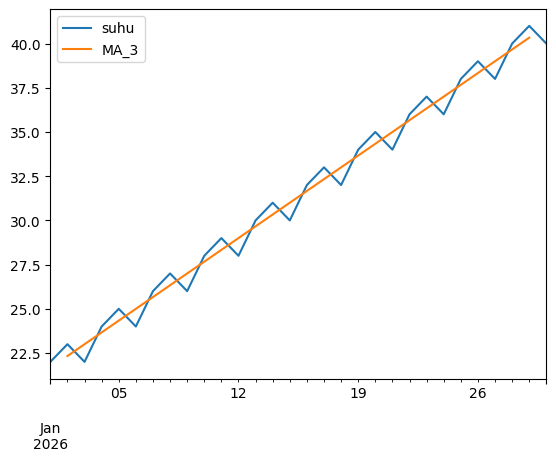

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Data contoh: suhu 30 hari, tren naik, sedikit noise
tanggal = pd.date_range("2026-01-01", periods=30, freq="D")
suhu = [22, 23, 22, 24, 25, 24, 26, 27, 26, 28, 29, 28, 30, 31, 30,
        32, 33, 32, 34, 35, 34, 36, 37, 36, 38, 39, 38, 40, 41, 40]
data = pd.DataFrame({"suhu": suhu}, index=tanggal)

# Jendela (window) 3 hari
# center=True menempatkan hasil rata-rata di tengah jendela
data["MA_3"] = data["suhu"].rolling(window=3, center=True).mean()

data.plot()
plt.show()

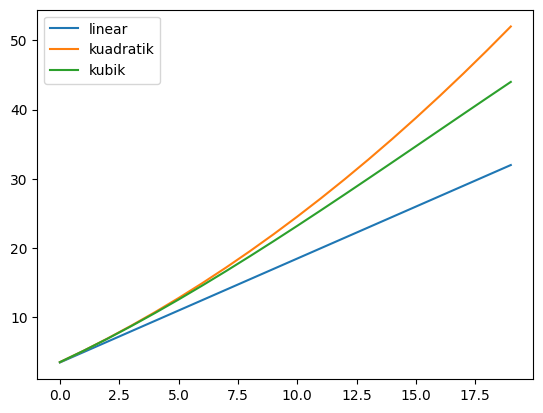

In [19]:
import numpy as np

t = np.arange(1, 21)  # waktu 1 sampai 20

linear = 2 + 1.5 * t
kuadratik = 2 + 1.5 * t + 0.05 * t**2
kubik = 2 + 1.5 * t + 0.05 * t**2 - 0.001 * t**3

pd.DataFrame({"linear": linear, "kuadratik": kuadratik, "kubik": kubik}).plot()
plt.show()

In [20]:
from statsmodels.tsa.deterministic import DeterministicProcess

dp = DeterministicProcess(index=data.index, constant=True, order=2, drop=True)
X = dp.in_sample()
X.head()

,const,trend,trend_squared
2026-01-01,1.0,1.0,1.0
2026-01-02,1.0,2.0,4.0
2026-01-03,1.0,3.0,9.0
2026-01-04,1.0,4.0,16.0
2026-01-05,1.0,5.0,25.0


In [21]:
data["tahun"] = data.index.year
data["bulan"] = data.index.month
data["hari"] = data.index.day
data["hari_ke"] = data.index.dayofweek  # Senin=0, Minggu=6

print(data.head())

            suhu       MA_3  tahun  bulan  hari  hari_ke
2026-01-01    22        NaN   2026      1     1        3
2026-01-02    23  22.333333   2026      1     2        4
2026-01-03    22  23.000000   2026      1     3        5
2026-01-04    24  23.666667   2026      1     4        6
2026-01-05    25  24.333333   2026      1     5        0


In [22]:
dummy = pd.get_dummies(data.index.day_name(), drop_first=True).astype(int)
print(dummy.head())

   Monday  Saturday  Sunday  Thursday  Tuesday  Wednesday
0       0         0       0         1        0          0
1       0         0       0         0        0          0
2       0         1       0         0        0          0
3       0         0       1         0        0          0
4       1         0       0         0        0          0


In [24]:
tanggal = pd.date_range("2026-01-01", periods=10, freq="D")
df = pd.DataFrame({"suhu": [22, 23, 24, 25, 26, 27, 28, 29, 30, 31]}, index=tanggal)

df = df.drop(df.index[4])
print("Sebelum asfreq, ada lubang:")
print(df)

# asfreq("D") mengembalikan tanggal yang hilang sebagai baris NaN
df = df.asfreq("D")
print("\nSetelah asfreq, lubang menjadi NaN:")
print(df)

# ffill mengisi NaN dengan nilai sebelumnya
df = df.ffill()
print("\nSetelah ffill, lubang terisi:")
print(df)

Sebelum asfreq, ada lubang:
            suhu
2026-01-01    22
2026-01-02    23
2026-01-03    24
2026-01-04    25
2026-01-06    27
2026-01-07    28
2026-01-08    29
2026-01-09    30
2026-01-10    31

Setelah asfreq, lubang menjadi NaN:
            suhu
2026-01-01  22.0
2026-01-02  23.0
2026-01-03  24.0
2026-01-04  25.0
2026-01-05   NaN
2026-01-06  27.0
2026-01-07  28.0
2026-01-08  29.0
2026-01-09  30.0
2026-01-10  31.0

Setelah ffill, lubang terisi:
            suhu
2026-01-01  22.0
2026-01-02  23.0
2026-01-03  24.0
2026-01-04  25.0
2026-01-05  25.0
2026-01-06  27.0
2026-01-07  28.0
2026-01-08  29.0
2026-01-09  30.0
2026-01-10  31.0
